#3B. You are a Computer Vision (CV) specialist. For dataset B, the goal is to train a VAE.

###import dataset

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/3.zip"
extract_path = "/content/data/"

if not os.path.exists(extract_path):
    os.makedirs(extract_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

os.listdir(extract_path)

['3', '__MACOSX']

In [3]:
os.path.exists("/content/drive/MyDrive/3.zip")


True

In [4]:
dataset_path = "/content/data/3"
img_size = 100

In [5]:
DATA_DIR = "/content/data"

print("Exists:", os.path.exists(DATA_DIR))
print("Isi /content/data:")
print(os.listdir(DATA_DIR))


Exists: True
Isi /content/data:
['3', '__MACOSX']


In [6]:
DATA_DIR = "/content/data/3"
print(os.listdir(DATA_DIR))


['train', 'validation', 'test', '.DS_Store']


In [7]:
!rm -f /content/data/3/.DS_Store


In [8]:
BASE_DIR = "/content/data/3"

for split in ["train", "validation", "test"]:
    split_path = os.path.join(BASE_DIR, split)
    print(f"\n{split.upper()}")
    print(os.listdir(split_path))



TRAIN
['rottenoranges', 'rottenapples', 'freshoranges', 'rottenbanana', 'freshapples', 'freshbanana', '.DS_Store']

VALIDATION
['rottenoranges', 'rottenapples', 'freshoranges', 'rottenbanana', 'freshapples', 'freshbanana', '.DS_Store']

TEST
['rottenoranges', 'rottenapples', 'freshoranges', 'rottenbanana', 'freshapples', 'freshbanana', '.DS_Store']


###3a. Analyze the provided dataset & state the discovered issues! Handle them accordingly! Resize the images to 100 x 100.

issues :
muncul file .DS_Store -> metadata macOS

handling : remove .DS_Store

In [9]:
!find /content/data/3 -name ".DS_Store" -delete

In [10]:
import cv2
sizes = set()

sample_dir = "/content/data/3/train/freshapples"

for img_name in os.listdir(sample_dir)[:20]:
    img = cv2.imread(os.path.join(sample_dir, img_name))
    if img is not None:
        sizes.add(img.shape[:2])

sizes


{(158, 168),
 (208, 198),
 (210, 226),
 (256, 240),
 (324, 324),
 (326, 322),
 (332, 362),
 (352, 366),
 (366, 308),
 (378, 388),
 (398, 422),
 (402, 416),
 (408, 400),
 (418, 432),
 (438, 374),
 (452, 470),
 (462, 472),
 (466, 478),
 (472, 404)}

issues :  resolusi image tidak konsisten

handling : resize semua gambar ke 100x100


issues :  urutan warna gambar BGR karena menggunakan cv2.imread()

handling : ubah ke RGB


issues :  ukuran pixel tidak konsisten

handling : normalize ke [0,1]


In [11]:
import os
import cv2
import numpy as np

IMG_SIZE = 100
BASE_DIR = "/content/data/3"

def load_images(split):
    images = []
    labels = []

    split_dir = os.path.join(BASE_DIR, split)

    for class_name in os.listdir(split_dir):
        class_path = os.path.join(split_dir, class_name)
        if not os.path.isdir(class_path):
            continue

        for img_name in os.listdir(class_path):
            img_path = os.path.join(class_path, img_name)

            img = cv2.imread(img_path)
            if img is None:
                continue

            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
            img = img / 255.0

            images.append(img)
            labels.append(class_name)

    return np.array(images), np.array(labels)

X_train, y_train = load_images("train")
X_val, y_val = load_images("validation")
X_test, y_test = load_images("test")

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (2778, 100, 100, 3)
Validation: (2353, 100, 100, 3)
Test: (90, 100, 100, 3)


###3b.  The encoder should have at least 3 2D Convolution layers & 2 2D Max Pooling layers. The decoder should have at least 2 layers. Make sure that the input & output shapes remain the same.
- The generator & decoder outputs should be 100 x 100 x 3!

In [12]:
import tensorflow as tf
from tensorflow.keras import layers, models, backend as K


In [13]:
input_img = layers.Input(shape=(100, 100, 3))

# Conv Block 1
x = layers.Conv2D(32, (3,3), activation='relu', padding='same')(input_img)
x = layers.MaxPooling2D((2,2), padding='same')(x)

# Conv Block 2
x = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2,2), padding='same')(x)

# Conv Block 3
x = layers.Conv2D(128, (3,3), activation='relu', padding='same')(x)

# Flatten
x = layers.Flatten()(x)
x = layers.Dense(256, activation='relu')(x)


In [14]:
latent_dim = 64

z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

def sampling(args):
    z_mean, z_log_var = args
    epsilon = K.random_normal(shape=(K.shape(z_mean)[0], latent_dim))
    return z_mean + K.exp(0.5 * z_log_var) * epsilon

z = layers.Lambda(sampling, name="z")([z_mean, z_log_var])


In [15]:
decoder_input = layers.Input(shape=(latent_dim,))

x = layers.Dense(25 * 25 * 128, activation='relu')(decoder_input)
x = layers.Reshape((25, 25, 128))(x)

# Upsampling Block 1
x = layers.Conv2DTranspose(128, (3,3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2,2))(x)

# Upsampling Block 2
x = layers.Conv2DTranspose(64, (3,3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2,2))(x)

# Output layer
output_img = layers.Conv2DTranspose(
    3, (3,3), activation='sigmoid', padding='same'
)(x)

In [16]:
encoder = models.Model(input_img, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 100, 100,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 50, 50,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 50, 50,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 25, 25,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 25, 25,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 80000)     │          0 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │ 20,480,256 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 64)        │     16,448 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 64)        │     16,448 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Lambda)          │ (None, 64)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 20,606,400 (78.61 MB)

 Trainable params: 20,606,400 (78.61 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
decoder = models.Model(decoder_input, output_img, name="decoder")
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 80000)          │     5,200,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 25, 25, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 50, 50, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 100, 100, 3)    │         1,731 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,423,107 (20.69 MB)

 Trainable params: 5,423,107 (20.69 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
vae_output = decoder(encoder(input_img)[2])
vae = models.Model(input_img, vae_output, name="VAE")

In [19]:
import keras
from keras import layers, ops
from keras.losses import binary_crossentropy

class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def call(self, inputs, training=False):
        z_mean, z_log_var, z = self.encoder(inputs, training=training)
        return self.decoder(z, training=training)

    def compute_vae_loss(self, data):
        z_mean, z_log_var, z = self.encoder(data, training=False)
        reconstruction = self.decoder(z, training=False)

        recon_loss = ops.mean(
            binary_crossentropy(data, reconstruction)
        ) * 100 * 100 * 3

        kl_loss = -0.5 * ops.mean(
            1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var)
        )

        total_loss = recon_loss + kl_loss
        return total_loss, recon_loss, kl_loss

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            total_loss, recon_loss, kl_loss = self.compute_vae_loss(data)

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        return {
            "loss": total_loss,
            "reconstruction_loss": recon_loss,
            "kl_loss": kl_loss,
        }

    def test_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        total_loss, recon_loss, kl_loss = self.compute_vae_loss(data)

        return {
            "loss": total_loss,
            "reconstruction_loss": recon_loss,
            "kl_loss": kl_loss,
        }


In [20]:
vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam())

In [21]:
history = vae.fit(
    X_train,
    validation_data=(X_val, None),
    epochs=15,
    batch_size=32
)

Epoch 1/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 23s 147ms/step - kl_loss: 36698192.0000 - loss: 36991360.0000 - reconstruction_loss: 293166.0625 - val_kl_loss: 1.5726 - val_loss: 16488.6621 - val_reconstruction_loss: 16487.0898
Epoch 2/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - kl_loss: 2.0137 - loss: 16002.8242 - reconstruction_loss: 16000.8105 - val_kl_loss: 3.6158 - val_loss: 11567.3125 - val_reconstruction_loss: 11563.6963
Epoch 3/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - kl_loss: 2.8651 - loss: 13808.0967 - reconstruction_loss: 13805.2314 - val_kl_loss: 4.0147 - val_loss: 9935.1924 - val_reconstruction_loss: 9931.1777
Epoch 4/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - kl_loss: 3.2850 - loss: 12965.3467 - reconstruction_loss: 12962.0615 - val_kl_loss: 4.2037 - val_loss: 9129.9766 - val_reconstruction_loss: 9125.7725
Epoch 5/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - kl_loss: 3.4452 - loss: 12602.0176 - reconstruction_loss: 12598.5723 - val_kl_loss: 4.4766 - val_loss: 8880.7637 - val

In [22]:
import matplotlib.pyplot as plt

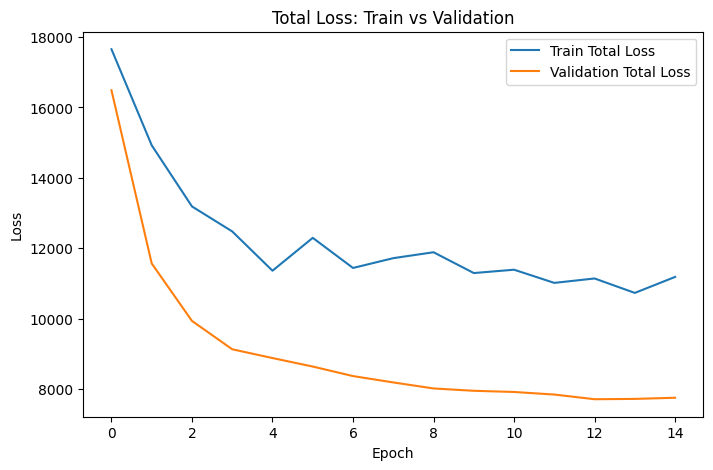

In [23]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Total Loss')
plt.plot(history.history['val_loss'], label='Validation Total Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Total Loss: Train vs Validation')
plt.legend()
plt.show()


###3c. Modify the model and analyze the impact of your modification on the model’s validation results! The modification may include changes in the model’s architecture (e.g. changing the layers,adding Batch Normalizations, etc.) or fine-tuning it. State the reasons behind the modifications!

In [31]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Conv2D, Conv2DTranspose, Dense, Flatten,
    Reshape, BatchNormalization, Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

In [35]:
latent_dim = 128

encoder_inputs = keras.Input(shape=(100, 100, 3))

x = layers.Conv2D(32, 3, activation="relu", padding="same")(encoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D()(x)

x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D()(x)

x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)

x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)

z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

In [36]:
def sampling(args):
    z_mean, z_log_var = args
    epsilon = tf.random.normal(shape=tf.shape(z_mean))
    return z_mean + tf.exp(0.5 * z_log_var) * epsilon

z = layers.Lambda(sampling)([z_mean, z_log_var])

encoder = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")

In [37]:
latent_inputs = keras.Input(shape=(latent_dim,))

x = layers.Dense(25 * 25 * 128, activation="relu")(latent_inputs)
x = layers.Reshape((25, 25, 128))(x)

x = layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)

x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)

x = layers.Conv2DTranspose(32, 3, strides=1, padding="same", activation="relu")(x)

decoder_outputs = layers.Conv2D(
    3, 3, activation="sigmoid", padding="same"
)(x)

decoder = keras.Model(latent_inputs, decoder_outputs, name="decoder")

In [48]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

        self.total_loss_tracker = keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs, training=False):
        z_mean, z_log_var, z = self.encoder(inputs, training=training)
        return self.decoder(z, training=training)

    #TRAIN
    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data, training=True)
            reconstruction = self.decoder(z, training=True)

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    keras.losses.binary_crossentropy(data, reconstruction),
                    axis=(1, 2)
                )
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                    axis=1
                )
            )

            total_loss = reconstruction_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    #VALIDATION
    def test_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        z_mean, z_log_var, z = self.encoder(data, training=False)
        reconstruction = self.decoder(z, training=False)

        reconstruction_loss = tf.reduce_mean(
            tf.reduce_sum(
                keras.losses.binary_crossentropy(data, reconstruction),
                axis=(1, 2)
            )
        )

        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                axis=1
            )
        )

        total_loss = reconstruction_loss + kl_loss

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }


In [49]:
vae_c = VAE(encoder, decoder)
vae_c.compile(optimizer=keras.optimizers.Adam(1e-4))

history_c = vae_c.fit(
    X_train,
    validation_data=X_val,
    epochs=15,
    batch_size=32
)

Epoch 1/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 26s 192ms/step - kl_loss: 209.2755 - loss: 4494.5522 - reconstruction_loss: 4285.2764 - val_kl_loss: 64.2522 - val_loss: 5904.3125 - val_reconstruction_loss: 5840.0605
Epoch 2/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 26s 80ms/step - kl_loss: 191.4442 - loss: 4357.1436 - reconstruction_loss: 4165.6992 - val_kl_loss: 95.3428 - val_loss: 5127.6274 - val_reconstruction_loss: 5032.2852
Epoch 3/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - kl_loss: 171.0729 - loss: 4298.2773 - reconstruction_loss: 4127.2041 - val_kl_loss: 102.9631 - val_loss: 4605.6250 - val_reconstruction_loss: 4502.6621
Epoch 4/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - kl_loss: 174.3666 - loss: 4165.8877 - reconstruction_loss: 3991.5215 - val_kl_loss: 105.4680 - val_loss: 4455.5771 - val_reconstruction_loss: 4350.1104
Epoch 5/15
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 78ms/step - kl_loss: 169.7602 - loss: 4125.5073 - reconstruction_loss: 3955.7466 - val_kl_loss: 132.4580 - val_loss: 4132.9546 - val_recon

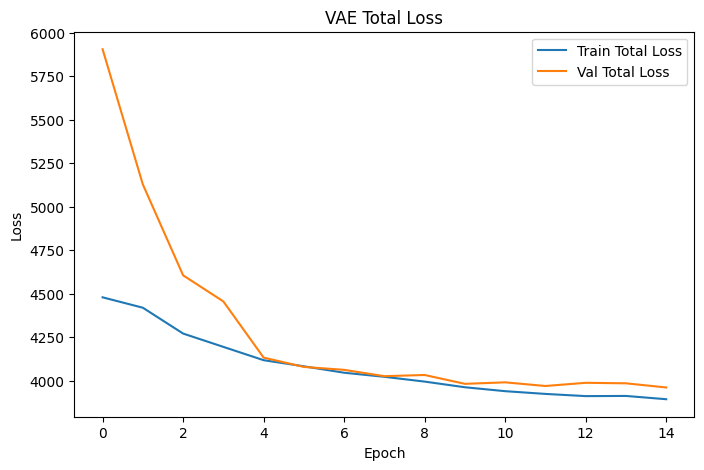

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history_c.history['loss'], label='Train Total Loss')
plt.plot(history_c.history['val_loss'], label='Val Total Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('VAE Total Loss')
plt.legend()
plt.show()

Di awal epoch, loss tinggi → model masih belajar

Loss turun stabil sampai akhir → model belajar dengan baik

Jarak train & validation tidak terlalu jauh → tidak overfitting

Di akhir epoch, grafik mulai mendatar → model sudah konvergen (belajar optimal)

Kesimpulan:

Training VAE berjalan stabil dan sehat.

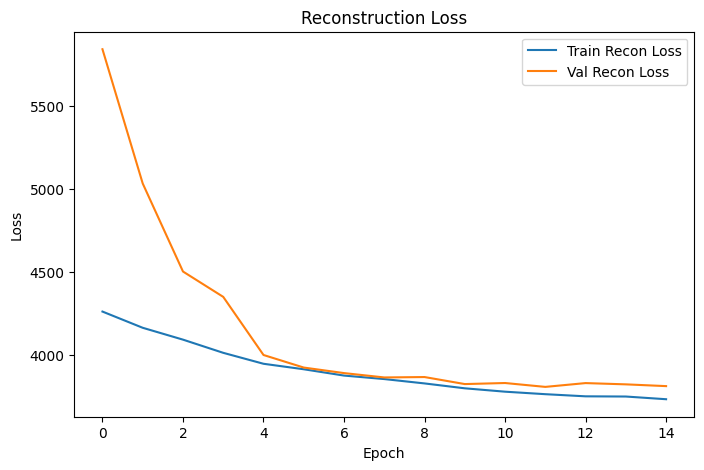

In [51]:
plt.figure(figsize=(8,5))
plt.plot(history_c.history['reconstruction_loss'], label='Train Recon Loss')
plt.plot(history_c.history['val_reconstruction_loss'], label='Val Recon Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Reconstruction Loss')
plt.legend()
plt.show()

Reconstruction loss turun konsisten

Validation loss sedikit lebih tinggi → normal

Tidak ada lonjakan besar → model generalisasi dengan baik

Kesimpulan: VAE makin lama makin jago merekonstruksi gambar, baik di train maupun validation.

###3d. Analyze how each model performs on the test set using FID for each class of the dataset. Interpret the meaning of the metric & make a conclusion!

In [58]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input
from scipy.linalg import sqrtm

In [59]:
inception = InceptionV3(
    include_top=False,
    pooling='avg',
    input_shape=(299, 299, 3)
)

In [60]:
from scipy.linalg import sqrtm

def calculate_fid(real_imgs, fake_imgs):
    # Resize ke 299x299 (syarat Inception)
    real_imgs = tf.image.resize(real_imgs, (299, 299))
    fake_imgs = tf.image.resize(fake_imgs, (299, 299))

    # Preprocess
    real_imgs = preprocess_input(real_imgs * 255.0)
    fake_imgs = preprocess_input(fake_imgs * 255.0)

    # Extract features
    real_features = inception.predict(real_imgs, verbose=0)
    fake_features = inception.predict(fake_imgs, verbose=0)

    # Mean & covariance
    mu1, sigma1 = real_features.mean(axis=0), np.cov(real_features, rowvar=False)
    mu2, sigma2 = fake_features.mean(axis=0), np.cov(fake_features, rowvar=False)

    # FID formula
    ssdiff = np.sum((mu1 - mu2) ** 2)
    covmean = sqrtm(sigma1 @ sigma2)

    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = ssdiff + np.trace(sigma1 + sigma2 - 2 * covmean)
    return fid

In [61]:
fid_per_class = {}

for cls in np.unique(y_test):
    idx = np.where(y_test == cls)[0]

    real_imgs = X_test[idx]
    recon_imgs = vae_c.predict(real_imgs, batch_size=32, verbose=0)

    fid_score = calculate_fid(real_imgs, recon_imgs)
    fid_per_class[cls] = fid_score

In [62]:
for cls, fid in fid_per_class.items():
    print(f"Class {cls} - FID: {fid:.2f}")

Class freshapples - FID: 384.84
Class freshbanana - FID: 525.28
Class freshoranges - FID: 421.48
Class rottenapples - FID: 404.32
Class rottenbanana - FID: 411.39
Class rottenoranges - FID: 374.32


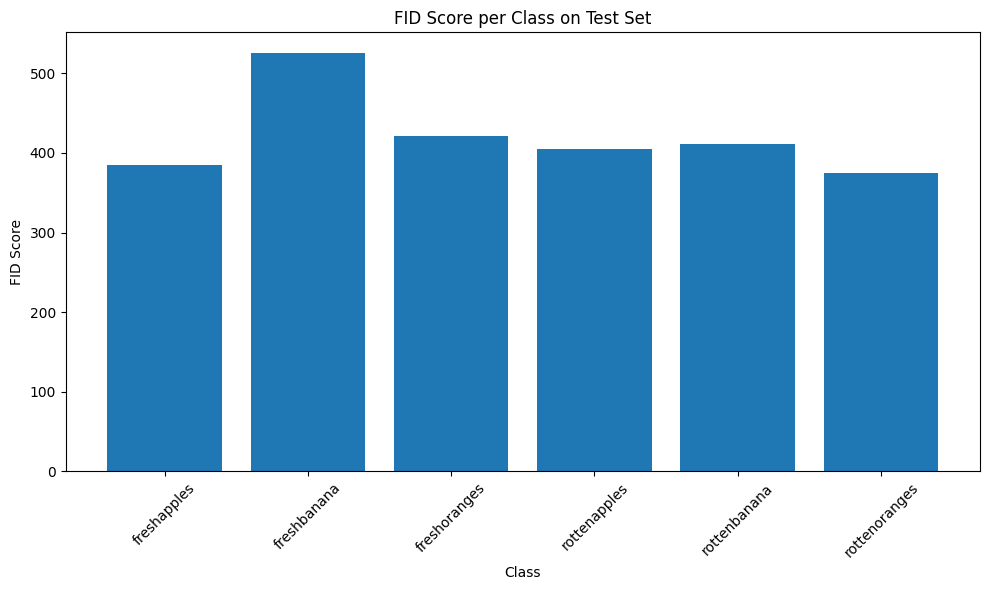

In [64]:
import matplotlib.pyplot as plt

classes = list(fid_per_class.keys())
values = list(fid_per_class.values())

plt.figure(figsize=(10, 6))
plt.bar(classes, values)
plt.xticks(rotation=45)
plt.ylabel("FID Score")
plt.xlabel("Class")
plt.title("FID Score per Class on Test Set")

plt.tight_layout()
plt.show()

Berdasarkan nilai FID yang relatif tinggi di seluruh kelas, kualitas gambar hasil generasi masih tergolong sedang, dengan performa terbaik pada kelas rottenoranges dan terburuk pada kelas freshbanana. Hal ini mengindikasikan bahwa meskipun struktur data telah dipelajari, peningkatan arsitektur atau jumlah data masih diperlukan untuk menghasilkan gambar yang lebih realistis.